 ## Libraries Import Karo

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All Libraries Imported Successfully!")

All Libraries Imported Successfully!


In [4]:
df = pd.read_csv("Unemployment in India.csv")

df.head()

FileNotFoundError: [Errno 2] No such file or directory: 'Unemployment in India.csv'

## Dataset Information

In [ ]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nDataset Columns:")
print(df.columns.tolist())

Dataset Shape: (768, 7)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 7 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Region                                    740 non-null    str    
 1    Date                                     740 non-null    str    
 2    Frequency                                740 non-null    str    
 3    Estimated Unemployment Rate (%)          740 non-null    float64
 4    Estimated Employed                       740 non-null    float64
 5    Estimated Labour Participation Rate (%)  740 non-null    float64
 6   Area                                      740 non-null    str    
dtypes: float64(3), str(4)
memory usage: 66.1 KB

Dataset Columns:
['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)', ' Estimated Employed', ' Estimated Labour Participation Rate (%)', 'Area']


In [ ]:
df.columns = df.columns.str.strip()

# Check missing values
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
Region                                     28
Date                                       28
Frequency                                  28
Estimated Unemployment Rate (%)            28
Estimated Employed                         28
Estimated Labour Participation Rate (%)    28
Area                                       28
dtype: int64


In [ ]:
empty_rows = df[df.isnull().all(axis=1)]

print("Completely Empty Rows:", len(empty_rows))

# Check rows containing any missing value
print("Rows with Missing Values:", df.isnull().any(axis=1).sum())

Completely Empty Rows: 28
Rows with Missing Values: 28


In [ ]:
# Remove completely empty rows
df.dropna(how='all', inplace=True)

# Reset index
df.reset_index(drop=True, inplace=True)

# Check updated dataset
print("Updated Dataset Shape:", df.shape)

# Check missing values again
print("\nMissing Values:")
print(df.isnull().sum())

Updated Dataset Shape: (740, 7)

Missing Values:
Region                                     0
Date                                       0
Frequency                                  0
Estimated Unemployment Rate (%)            0
Estimated Employed                         0
Estimated Labour Participation Rate (%)    0
Area                                       0
dtype: int64


In [ ]:
# Convert Date column to datetime
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True)

# Check data types
print(df.dtypes)

# Display first 5 rows
df.head()

Region                                                str
Date                                       datetime64[us]
Frequency                                             str
Estimated Unemployment Rate (%)                   float64
Estimated Employed                                float64
Estimated Labour Participation Rate (%)           float64
Area                                                  str
dtype: object


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,2019-05-31,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,2019-06-30,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,2019-07-31,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,2019-08-31,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,2019-09-30,Monthly,5.17,12256762.0,44.68,Rural


In [ ]:
# Statistical summary of numerical columns
df.describe()

,Date,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
count,740,740.000000,7.400000e+02,740.000000
mean,2019-12-12 18:36:58.378378,11.787946,7.204460e+06,42.630122
min,2019-05-31 00:00:00,0.000000,4.942000e+04,13.330000
25%,2019-08-31 00:00:00,4.657500,1.190404e+06,38.062500
50%,2019-11-30 00:00:00,8.350000,4.744178e+06,41.160000
75%,2020-03-31 00:00:00,15.887500,1.127549e+07,45.505000
max,2020-06-30 00:00:00,76.740000,4.577751e+07,72.570000
std,NaN,10.721298,8.087988e+06,8.111094


In [ ]:
# Check unique Regions and Areas
print("Total Regions:", df['Region'].nunique())
print("\nRegions:")
print(df['Region'].unique())

print("\nAreas:")
print(df['Area'].unique())

Total Regions: 28

Regions:
<ArrowStringArray>
[  'Andhra Pradesh',            'Assam',            'Bihar',
     'Chhattisgarh',            'Delhi',              'Goa',
          'Gujarat',          'Haryana', 'Himachal Pradesh',
  'Jammu & Kashmir',        'Jharkhand',        'Karnataka',
           'Kerala',   'Madhya Pradesh',      'Maharashtra',
        'Meghalaya',           'Odisha',       'Puducherry',
           'Punjab',        'Rajasthan',           'Sikkim',
       'Tamil Nadu',        'Telangana',          'Tripura',
    'Uttar Pradesh',      'Uttarakhand',      'West Bengal',
       'Chandigarh']
Length: 28, dtype: str

Areas:
<ArrowStringArray>
['Rural', 'Urban']
Length: 2, dtype: str


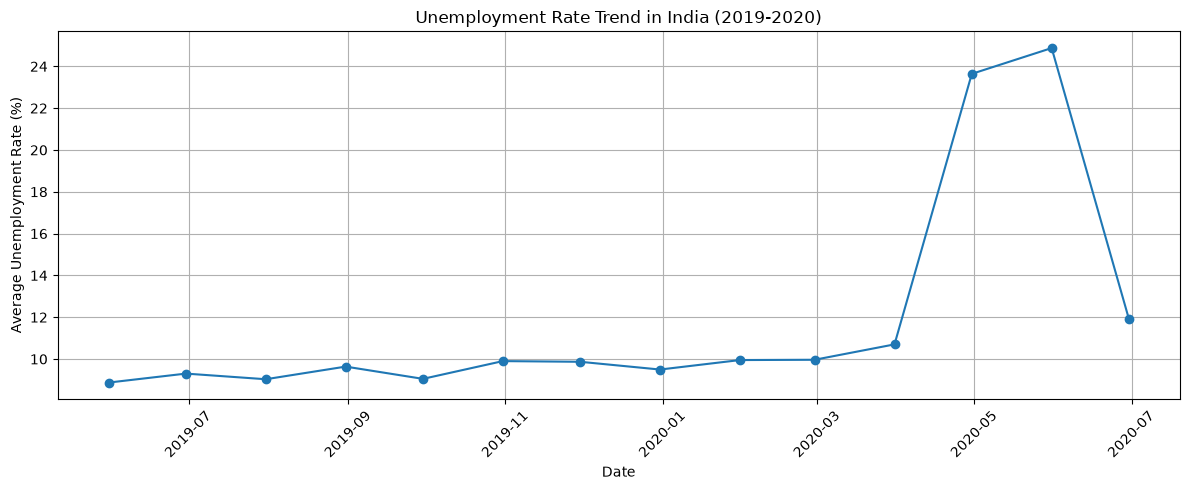

In [ ]:
# Calculate average unemployment rate by date
monthly_unemployment = df.groupby('Date')[
    'Estimated Unemployment Rate (%)'
].mean()

# Plot the trend
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_unemployment.index,
    monthly_unemployment.values,
    marker='o'
)

plt.title('Unemployment Rate Trend in India (2019-2020)')
plt.xlabel('Date')
plt.ylabel('Average Unemployment Rate (%)')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
# Define COVID periods
pre_covid = df[df['Date'] < '2020-03-01']

covid_period = df[
    (df['Date'] >= '2020-03-01') &
    (df['Date'] <= '2020-06-30')
]

# Calculate average unemployment rates
pre_covid_rate = pre_covid['Estimated Unemployment Rate (%)'].mean()

covid_rate = covid_period['Estimated Unemployment Rate (%)'].mean()

print("Average Unemployment Rate Before COVID:",
      round(pre_covid_rate, 2), "%")

print("Average Unemployment Rate During COVID:",
      round(covid_rate, 2), "%")

print("Increase in Unemployment Rate:",
      round(covid_rate - pre_covid_rate, 2), "percentage points")

Average Unemployment Rate Before COVID: 9.51 %
Average Unemployment Rate During COVID: 17.77 %
Increase in Unemployment Rate: 8.26 percentage points


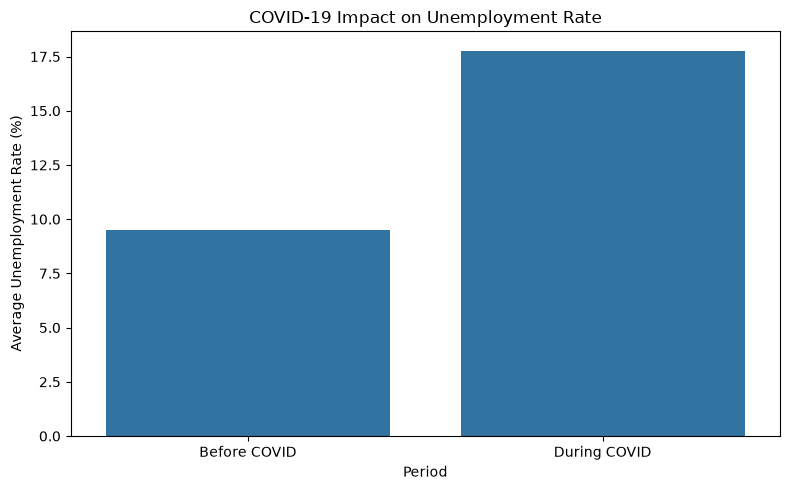

In [ ]:
# Prepare comparison data
comparison = pd.DataFrame({
    'Period': ['Before COVID', 'During COVID'],
    'Unemployment Rate': [pre_covid_rate, covid_rate]
})

# Create bar chart
plt.figure(figsize=(8, 5))

sns.barplot(
    data=comparison,
    x='Period',
    y='Unemployment Rate'
)

plt.title('COVID-19 Impact on Unemployment Rate')
plt.xlabel('Period')
plt.ylabel('Average Unemployment Rate (%)')

plt.tight_layout()
plt.show()

In [ ]:
# Calculate average unemployment rate by region
state_unemployment = df.groupby('Region')[
    'Estimated Unemployment Rate (%)'
].mean().sort_values(ascending=False)

print("State-wise Average Unemployment Rate:")
print(state_unemployment.round(2))

State-wise Average Unemployment Rate:
Region
Tripura             28.35
Haryana             26.28
Jharkhand           20.58
Bihar               18.92
Himachal Pradesh    18.54
Delhi               16.50
Jammu & Kashmir     16.19
Chandigarh          15.99
Rajasthan           14.06
Uttar Pradesh       12.55
Punjab              12.03
Puducherry          10.22
Kerala              10.12
Tamil Nadu           9.28
Goa                  9.27
Chhattisgarh         9.24
West Bengal          8.12
Telangana            7.74
Maharashtra          7.56
Andhra Pradesh       7.48
Madhya Pradesh       7.41
Sikkim               7.25
Karnataka            6.68
Gujarat              6.66
Uttarakhand          6.58
Assam                6.43
Odisha               5.66
Meghalaya            4.80
Name: Estimated Unemployment Rate (%), dtype: float64


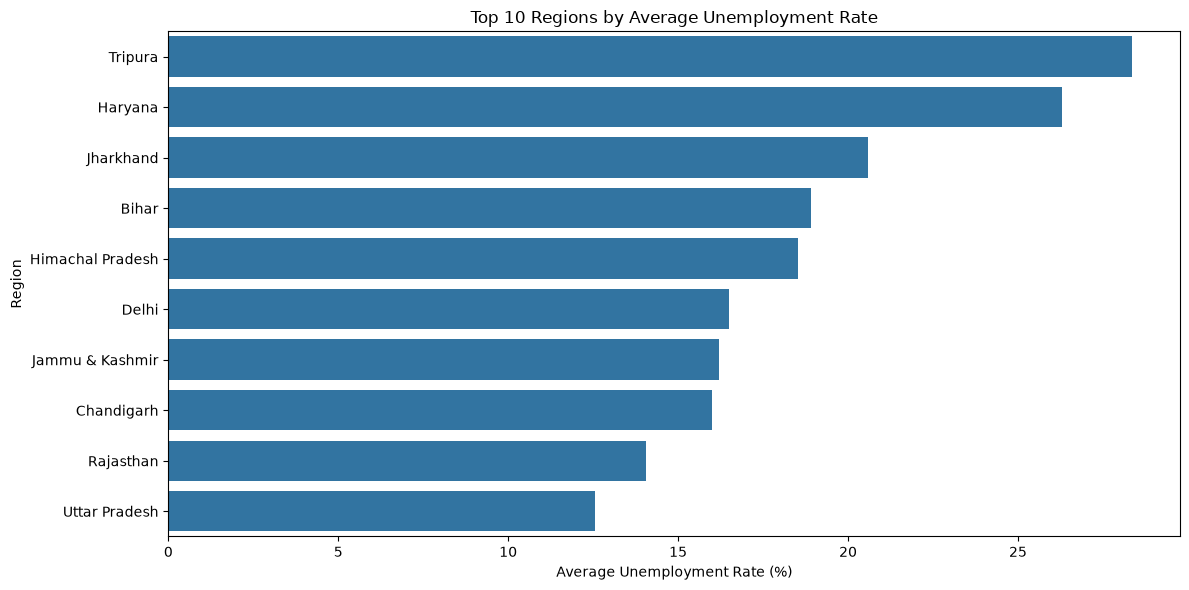

In [ ]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=state_unemployment.head(10).values,
    y=state_unemployment.head(10).index
)

plt.title('Top 10 Regions by Average Unemployment Rate')
plt.xlabel('Average Unemployment Rate (%)')
plt.ylabel('Region')

plt.tight_layout()
plt.show()

In [ ]:
# Calculate average unemployment rate by Area
area_unemployment = df.groupby('Area')[
    'Estimated Unemployment Rate (%)'
].mean()

print("Rural vs Urban Unemployment:")
print(area_unemployment.round(2))

Rural vs Urban Unemployment:
Area
Rural    10.32
Urban    13.17
Name: Estimated Unemployment Rate (%), dtype: float64


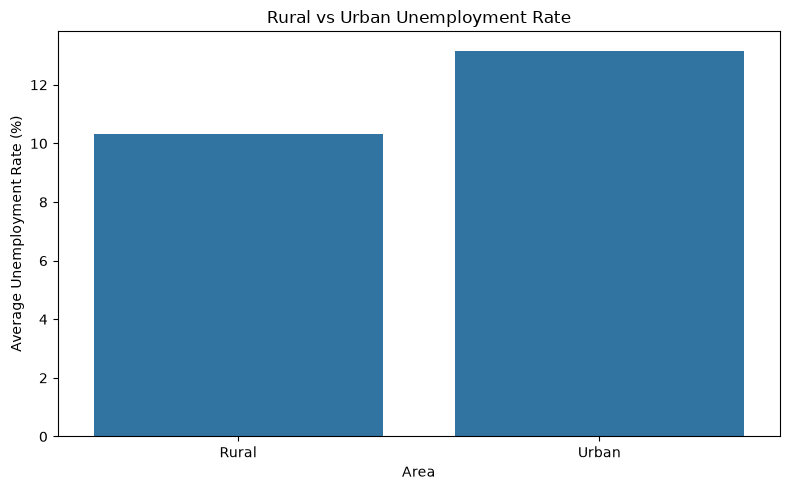

In [ ]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=area_unemployment.index,
    y=area_unemployment.values
)

plt.title('Rural vs Urban Unemployment Rate')
plt.xlabel('Area')
plt.ylabel('Average Unemployment Rate (%)')

plt.tight_layout()
plt.show()

In [ ]:
print("========== UNEMPLOYMENT ANALYSIS ==========")

print("\n1. Dataset Information")
print("Total Records:", len(df))
print("Total Regions:", df['Region'].nunique())

print("\n2. Overall Unemployment Rate")
print("Average:", round(df['Estimated Unemployment Rate (%)'].mean(), 2), "%")

print("\n3. COVID-19 Impact")
print("Before COVID:", round(pre_covid_rate, 2), "%")
print("During COVID:", round(covid_rate, 2), "%")

print("\n4. Highest Unemployment Region")
print(state_unemployment.idxmax(), "-", round(state_unemployment.max(), 2), "%")

print("\n5. Bihar Unemployment Rate")
print(round(state_unemployment['Bihar'], 2), "%")

print("\n6. Rural vs Urban")
print(area_unemployment.round(2))

print("\n========== ANALYSIS COMPLETED ==========")

========== UNEMPLOYMENT ANALYSIS ==========

1. Dataset Information
Total Records: 740
Total Regions: 28

2. Overall Unemployment Rate
Average: 11.79 %

3. COVID-19 Impact
Before COVID: 9.51 %
During COVID: 17.77 %

4. Highest Unemployment Region
Tripura - 28.35 %

5. Bihar Unemployment Rate
18.92 %

6. Rural vs Urban
Area
Rural    10.32
Urban    13.17
Name: Estimated Unemployment Rate (%), dtype: float64

========== ANALYSIS COMPLETED ==========


In [ ]:
print("Unemployment Analysis - VS Code Ready!")

Unemployment Analysis - VS Code Ready!


In [ ]:
import pandas as pd

df = pd.read_csv("../dataset/Unemployment in India.csv")

print("Dataset Loaded Successfully!")
print("Shape:", df.shape)

df.head()

Dataset Loaded Successfully!
Shape: (768, 7)


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural
